# 01 Numercal PrePreprocessing

# **PreProcessing for Task A**

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import MinMaxScaler, OneHotEncoder
import joblib
from sklearn.linear_model import LinearRegression
from sklearn.metrics import root_mean_squared_error, mean_absolute_error, r2_score
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (accuracy_score, confusion_matrix, classification_report,silhouette_score,adjusted_rand_score)
from sklearn.utils.validation import check_is_fitted

In [2]:
medical_df = pd.read_csv('https://raw.githubusercontent.com/nour-ehab/ML-Project/refs/heads/main/part_a_numerical/data/insurance.csv')
medical_df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


# **EDA**

In [3]:
# Statistical summary
print(medical_df.describe(include="all"))

                age   sex          bmi     children smoker     region  \
count   1338.000000  1338  1338.000000  1338.000000   1338       1338   
unique          NaN     2          NaN          NaN      2          4   
top             NaN  male          NaN          NaN     no  southeast   
freq            NaN   676          NaN          NaN   1064        364   
mean      39.207025   NaN    30.663397     1.094918    NaN        NaN   
std       14.049960   NaN     6.098187     1.205493    NaN        NaN   
min       18.000000   NaN    15.960000     0.000000    NaN        NaN   
25%       27.000000   NaN    26.296250     0.000000    NaN        NaN   
50%       39.000000   NaN    30.400000     1.000000    NaN        NaN   
75%       51.000000   NaN    34.693750     2.000000    NaN        NaN   
max       64.000000   NaN    53.130000     5.000000    NaN        NaN   

             charges  
count    1338.000000  
unique           NaN  
top              NaN  
freq             NaN  
mean    

In [4]:
medical_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB


In [5]:
# Missing values count
print("Missing values count:")
print(medical_df.isnull().sum())

Missing values count:
age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64


In [6]:
# Duplicate rows count and removal
print("Number of duplicate rows:", medical_df.duplicated().sum())
medical_df = medical_df.drop_duplicates()
print("Number of duplicate rows:", medical_df.duplicated().sum())

Number of duplicate rows: 1
Number of duplicate rows: 0


In [7]:
# Value counts
print("Value counts for 'sex':")
print(medical_df["sex"].value_counts())

Value counts for 'sex':
sex
male      675
female    662
Name: count, dtype: int64


In [8]:
print("Value counts for 'smoker':")
print(medical_df["smoker"].value_counts())

Value counts for 'smoker':
smoker
no     1063
yes     274
Name: count, dtype: int64


In [9]:
print("Value counts for 'region':")
print(medical_df["region"].value_counts())

Value counts for 'region':
region
southeast    364
southwest    325
northwest    324
northeast    324
Name: count, dtype: int64


In [10]:
# Average charges by smoker
print("Average charges by smoker:")
print(medical_df.groupby("smoker")["charges"].mean())

Average charges by smoker:
smoker
no      8440.660307
yes    32050.231832
Name: charges, dtype: float64


In [11]:
# Average charges by sex and smoker
print("Average charges by sex and smoker:")
print(medical_df.groupby(["sex", "smoker"])["charges"].mean())

Average charges by sex and smoker:
sex     smoker
female  no         8762.297300
        yes       30678.996276
male    no         8099.700161
        yes       33042.005975
Name: charges, dtype: float64


In [12]:
# Correlation with charges
print("Correlation with charges:")
print(
    medical_df.corr(numeric_only=True)["charges"]
    .sort_values(ascending=False)
)

Correlation with charges:
charges     1.000000
age         0.298308
bmi         0.198401
children    0.067389
Name: charges, dtype: float64


Outlier Detection

In [13]:
Q1 = medical_df["charges"].quantile(0.25)
Q3 = medical_df["charges"].quantile(0.75)
IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

outliers = medical_df[
    (medical_df["charges"] < lower) |
    (medical_df["charges"] > upper)
]

print("Number of outliers:", len(outliers))
print(
    "Outliers percentage:",
    int(len(outliers) / len(medical_df) * 100),
    "%"
)

Number of outliers: 139
Outliers percentage: 10 %


Plotting

In [14]:
plt.figure(figsize=(10, 6))

<Figure size 1000x600 with 0 Axes>

<Figure size 1000x600 with 0 Axes>

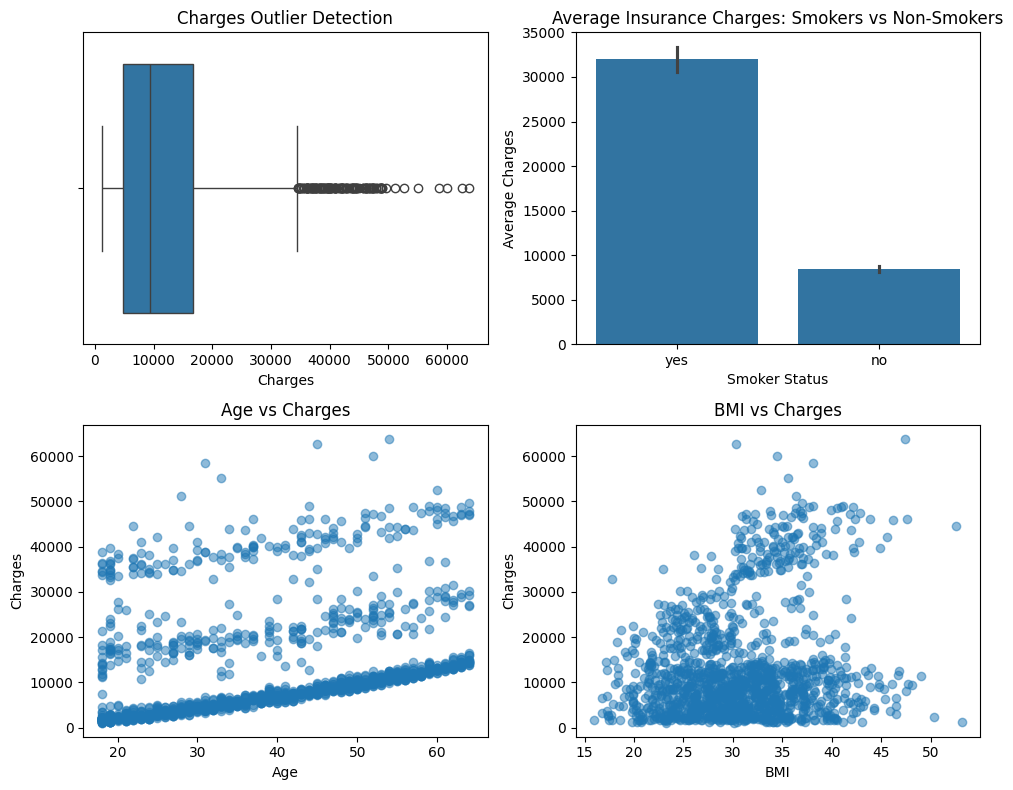

In [15]:
fig, axes = plt.subplots(2, 2, figsize=(10, 8))

# 1. Charges outliers
sns.boxplot(x=medical_df["charges"], ax=axes[0, 0])
axes[0, 0].set_title("Charges Outlier Detection")
axes[0, 0].set_xlabel("Charges")

# 2. Relationship between Age and Charges
axes[1, 0].scatter(
    medical_df["age"],
    medical_df["charges"],
    alpha=0.5
)
axes[1, 0].set_title("Age vs Charges")
axes[1, 0].set_xlabel("Age")
axes[1, 0].set_ylabel("Charges")

# 3. Relationship between BMI and Charges
axes[1, 1].scatter(
    medical_df["bmi"],
    medical_df["charges"],
    alpha=0.5
)
axes[1, 1].set_title("BMI vs Charges")
axes[1, 1].set_xlabel("BMI")
axes[1, 1].set_ylabel("Charges")

# 4. Relationship between smokers , non_smokers and Charges
sns.barplot(
    data=medical_df,
    x="smoker",
    y="charges",
    estimator="mean",
    ax=axes[0, 1]
)
axes[0, 1].set_xlabel("Smoker Status")
axes[0, 1].set_ylabel("Average Charges")
axes[0, 1].set_title("Average Insurance Charges: Smokers vs Non-Smokers")

plt.tight_layout()
plt.show()

# **Data Cleaning**

In [16]:
# Remove rows with missing target values
medical_df = medical_df.dropna(subset=["charges"])

# Separate smokers and non-smokers
non_smoker = medical_df[medical_df["smoker"] == "no"]
smoker = medical_df[medical_df["smoker"] == "yes"]

In [17]:
medical_df_without_charges = medical_df.drop(columns=["charges"])
inputs = medical_df_without_charges
target = medical_df["charges"]

num_cols = inputs.select_dtypes(include=["number"]).columns.tolist()
cat_cols = inputs.select_dtypes(include=["string", "category"]).columns.tolist()

# Optional: inspect selected columns
print("Numeric columns:", num_cols)
print("Categorical columns:", cat_cols)

Numeric columns: ['age', 'bmi', 'children']
Categorical columns: []


# **Split Dataset into Train, Validation, and Test Sets (70/15/15)**

In [18]:
# Split before preprocessing to avoid data leakage
X_train, X_temp, y_train, y_temp = train_test_split(
    inputs,
    target,
    test_size=0.30,
    random_state=42
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42
)

# **Preprocessing Pipelines**

In [19]:
# Numerical pipeline
num_pipes = make_pipeline(
    SimpleImputer(strategy="mean"),
    MinMaxScaler()
)

# Categorical pipeline
cat_pipes = make_pipeline(
    SimpleImputer(strategy="most_frequent"),
    OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False,
        drop="if_binary"
    )
)

# Apply the appropriate pipeline to each column type
preprocessing = ColumnTransformer([
    ("num", num_pipes, num_cols),
    ("cat", cat_pipes, cat_cols)
])

In [20]:
train_pre = preprocessing.fit_transform(X_train)
val_pre = preprocessing.transform(X_val)
test_pre = preprocessing.transform(X_test)

In [21]:
enc_cols = list(
    preprocessing.named_transformers_["cat"]
    .named_steps["onehotencoder"]
    .get_feature_names_out(cat_cols)
)

NotFittedError: This OneHotEncoder instance is not fitted yet. Call 'fit' with appropriate arguments before using this estimator.

In [ ]:
enc_cols


In [ ]:
X_train_pre = pd.DataFrame(
    train_pre,
    columns=num_cols + enc_cols,
    index=X_train.index
)

X_val_pre = pd.DataFrame(
    val_pre,
    columns=num_cols + enc_cols,
    index=X_val.index
)

X_test_pre = pd.DataFrame(
    test_pre,
    columns=num_cols + enc_cols,
    index=X_test.index
)

print("Training set shape:", X_train_pre.shape)
print("Validation set shape:", X_val_pre.shape)
print("Test set shape:", X_test_pre.shape)

In [ ]:
X_train_pre.head()

In [ ]:
X_test_pre.to_csv('data/X_test_pre.csv', index=False)
X_train_pre.to_csv('data/X_train_pre.csv', index=False)
X_val_pre.to_csv('data/X_val_pre.csv', index=False)
y_test.to_csv('data/y_test.csv', index=False)
y_train.to_csv('data/y_train.csv', index=False)
y_val.to_csv('data/y_val.csv', index=False)

In [ ]:
joblib.dump(preprocessing, '../models/numerical_preprocessing.pkl')

# 02 LinearRegression

# Part A: Linear Regression

In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import root_mean_squared_error, mean_absolute_error, r2_score
import matplotlib.pyplot as plt
import joblib
import pandas as pd

## Load data and build the pipeline

In [7]:
X_train, X_val, X_test, y_train, y_val, y_test = pd.read_csv('data/X_train_pre.csv'), pd.read_csv('data/X_val_pre.csv'), pd.read_csv('data/X_test_pre.csv'), pd.read_csv('data/y_train.csv'), pd.read_csv('data/y_val.csv'), pd.read_csv('data/y_test.csv')

In [8]:
lg = LinearRegression()

## Train and predict

In [9]:
lg.fit(X_train, y_train)
y_pred = lg.predict(X_test)

## Metrics on the test set

In [10]:
print(f"Root Mean Squared Error {root_mean_squared_error(y_test, y_pred)}")
print(f"Mean Absolute Error {mean_absolute_error(y_test, y_pred)}")
print(f"R Squared Score {r2_score(y_test, y_pred)}")

Root Mean Squared Error 6162.78107899311
Mean Absolute Error 4041.9146181642636
R Squared Score 0.7774494528447099


## Predicted vs Actual

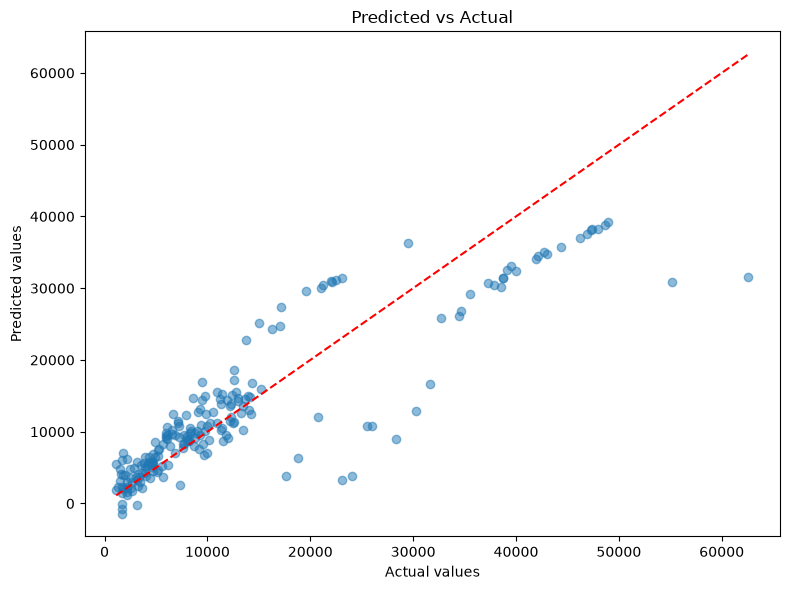

In [11]:
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred, alpha=0.5)
# perfect prediction line >>> pred = actual
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    "r--")
plt.xlabel("Actual values")
plt.ylabel("Predicted values")
plt.title("Predicted vs Actual")
plt.tight_layout()
plt.show()

## Save the model

In [13]:
joblib.dump(lg, '../models/LinearReg.pkl')

['../models/LinearReg.pkl']

# 03 knn regressor

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import os
import numpy as np

DATA_PATH = '/content/drive/MyDrive/ML Project/ML-Project-main/ML-Project-main/part_b_images/data'

data = np.load(os.path.join(DATA_PATH, 'split_scaled.npz'))

X_train_scaled = data['X_train_scaled']
X_val_scaled = data['X_val_scaled']
X_test_scaled = data['X_test_scaled']

y_train = data['y_train']
y_val = data['y_val']
y_test = data['y_test']

In [4]:
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (accuracy_score, confusion_matrix, classification_report,
                             silhouette_score, adjusted_rand_score)

In [5]:
# KNN: tune k and weights on the validation set
knn_val_acc = {}
for weights in ["uniform", "distance"]:
    for k in [1, 3, 5, 7, 9, 11, 15, 21]:
        model = KNeighborsClassifier(n_neighbors=k, weights=weights).fit(X_train_scaled, y_train)
        knn_val_acc[(k, weights)] = accuracy_score(y_val, model.predict(X_val_scaled))
        print(f"KNN k={k:<3} weights={weights:<9} val acc = {knn_val_acc[(k, weights)]:.4f}")
best_k, best_w = max(knn_val_acc, key=lambda kw: (knn_val_acc[kw], kw[0], kw[1] == "uniform"))
print("Best KNN:", best_k, best_w)

KNN k=1   weights=uniform   val acc = 1.0000
KNN k=3   weights=uniform   val acc = 1.0000
KNN k=5   weights=uniform   val acc = 1.0000
KNN k=7   weights=uniform   val acc = 1.0000
KNN k=9   weights=uniform   val acc = 1.0000
KNN k=11  weights=uniform   val acc = 1.0000
KNN k=15  weights=uniform   val acc = 1.0000
KNN k=21  weights=uniform   val acc = 1.0000
KNN k=1   weights=distance  val acc = 1.0000
KNN k=3   weights=distance  val acc = 1.0000
KNN k=5   weights=distance  val acc = 1.0000
KNN k=7   weights=distance  val acc = 1.0000
KNN k=9   weights=distance  val acc = 1.0000
KNN k=11  weights=distance  val acc = 1.0000
KNN k=15  weights=distance  val acc = 1.0000
KNN k=21  weights=distance  val acc = 1.0000
Best KNN: 21 uniform


In [6]:
# KNN
knn_model = KNeighborsClassifier(n_neighbors=best_k, weights=best_w)
knn_model.fit(X_train_scaled, y_train)
y_pred_knn = knn_model.predict(X_test_scaled)

print("KNN")
print("Accuracy:", accuracy_score(y_test, y_pred_knn))

KNN
Accuracy: 1.0


# 04 comparison

# Comparison Between LinearRegression and KNN Models

In [1]:
import joblib
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    root_mean_squared_error,
    mean_absolute_error,
    r2_score)
from sklearn.utils.validation import check_is_fitted

In [2]:
X_test = pd.read_csv('data/X_test_pre.csv')
y_test = pd.read_csv('data/y_test.csv').squeeze('columns')

print("X_test shape:", X_test.shape)
print("y_test shape:", y_test.shape)

X_test shape: (201, 9)
y_test shape: (201,)


In [3]:
linear_model = joblib.load('../models/LinearReg.pkl')
knn_model = joblib.load('../models/knn_regressor.pkl')

d:\Project\.venv\Lib\site-packages\sklearn\base.py:525: InconsistentVersionWarning: Trying to unpickle estimator LinearRegression from version 1.9.1 when using version 1.9.0. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
d:\Project\.venv\Lib\site-packages\sklearn\base.py:525: InconsistentVersionWarning: Trying to unpickle estimator KNeighborsRegressor from version 1.9.1 when using version 1.9.0. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(


In [4]:
# This check prevents evaluation of an unfitted model.
check_is_fitted(linear_model)

try:
    check_is_fitted(knn_model)
except Exception as error:
    raise RuntimeError(
        "The saved KNN model is not fitted. "
        ) from error

print("Both models are fitted and ready for comparison.")

Both models are fitted and ready for comparison.


In [5]:
linear_pred = linear_model.predict(X_test)
knn_pred = knn_model.predict(X_test)

6. Compare Evaluation Metrics

- RMSE: lower is better.
- MAE: lower is better.
- R²: higher is better.

In [6]:
results = pd.DataFrame({
    'Model': ['Linear Regression', 'KNN Regressor'],
    
    'RMSE': [
        root_mean_squared_error(y_test, linear_pred),
        root_mean_squared_error(y_test, knn_pred)],
    
    'MAE': [
        mean_absolute_error(y_test, linear_pred),
        mean_absolute_error(y_test, knn_pred)],
    
    'R2': [
        r2_score(y_test, linear_pred),
        r2_score(y_test, knn_pred)]
    
}).set_index('Model')

display(results.round(3))

,RMSE,MAE,R2
Model,,,
Linear Regression,6162.781,4041.915,0.777
KNN Regressor,6213.401,3909.543,0.774


Plotting Comparison

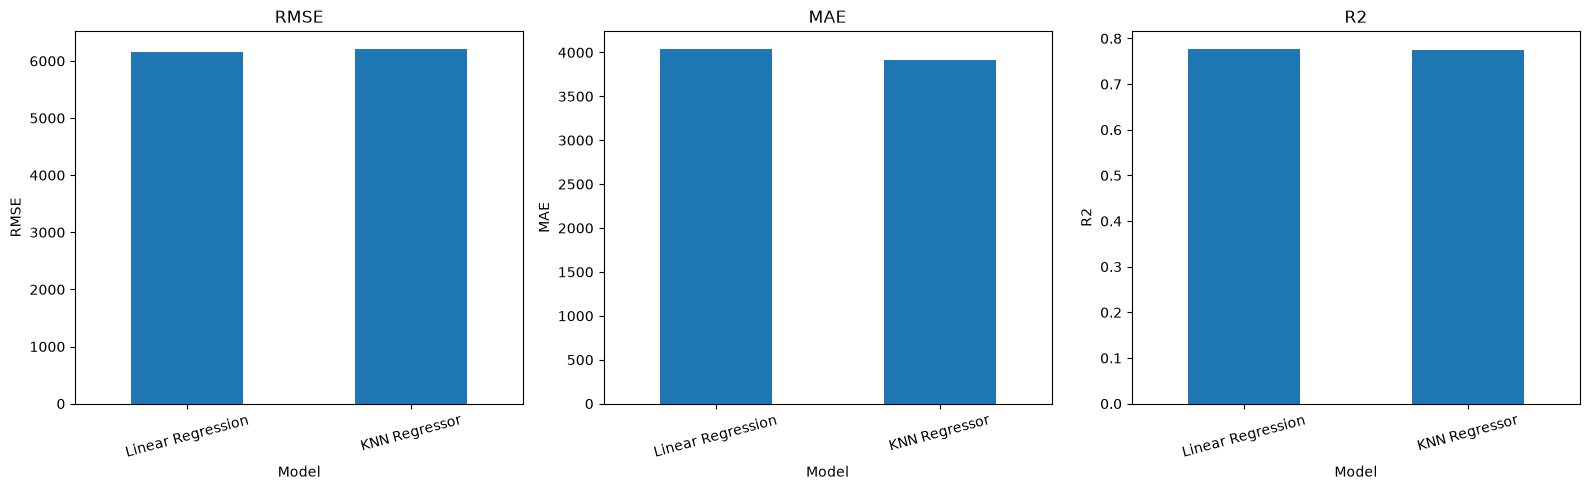

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, metric in zip(axes, ['RMSE', 'MAE', 'R2']):
    results[metric].plot(kind='bar', ax=ax)
    ax.set_title(metric)
    ax.set_xlabel('Model')
    ax.set_ylabel(metric)
    ax.tick_params(axis='x', rotation=15)

plt.tight_layout()
plt.show()

## 8. Actual vs Predicted

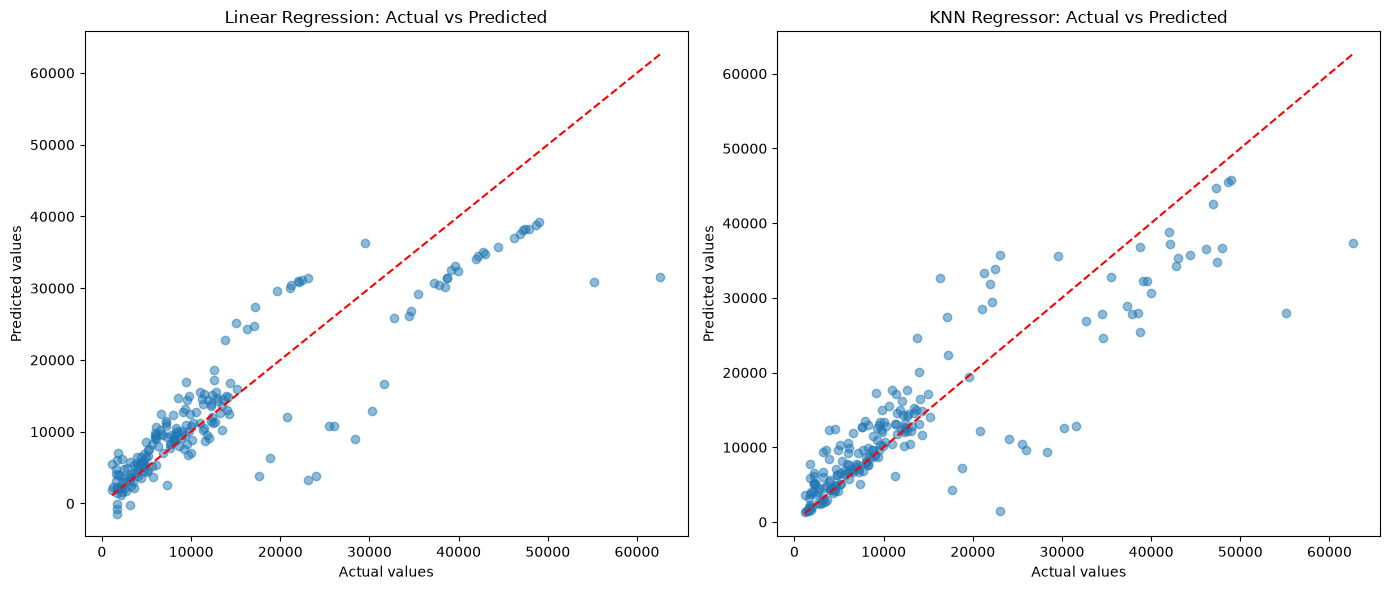

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

predictions = {
    'Linear Regression': linear_pred,
    'KNN Regressor': knn_pred}

for ax, (name, pred) in zip(axes, predictions.items()):
    ax.scatter(y_test, pred, alpha=0.5)
    ax.plot(
        [y_test.min(), y_test.max()],
        [y_test.min(), y_test.max()],
        'r--'
    )
    ax.set_xlabel('Actual values')
    ax.set_ylabel('Predicted values')
    ax.set_title(f'{name}: Actual vs Predicted')

plt.tight_layout()
plt.show()

## 9. Residual Comparison

Residual = Actual - Predicted. A residual distribution concentrated around zero is generally preferable.

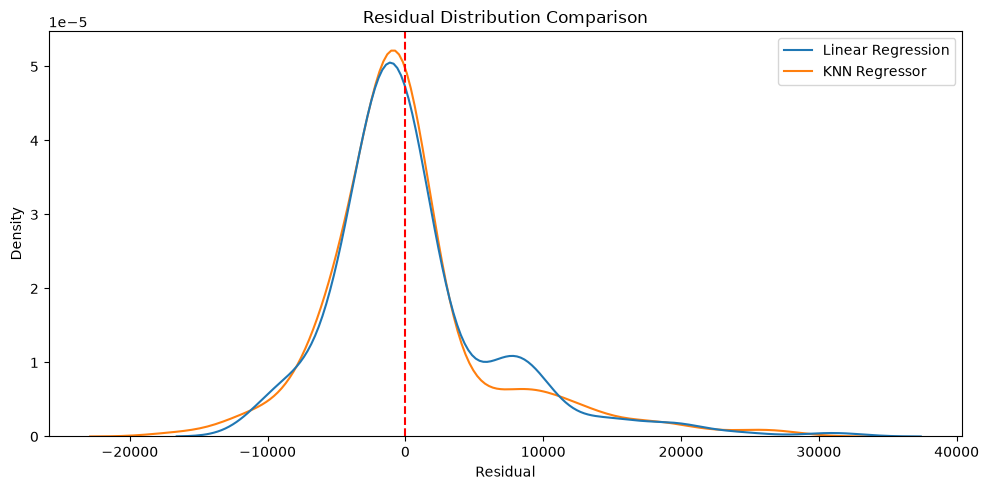

In [9]:
residuals = pd.DataFrame({
    'Linear Regression': y_test - linear_pred.ravel(),
    'KNN Regressor': y_test - knn_pred.ravel()
})

plt.figure(figsize=(10, 5))
sns.kdeplot(data=residuals, fill=False)
plt.axvline(0, color='red', linestyle='--')
plt.xlabel('Residual')
plt.title('Residual Distribution Comparison')
plt.tight_layout()
plt.show()

## 10. Best Model

The model with the lowest test RMSE is selected by this comparison. MAE and R² are also considered.

In [ ]:
best_model_name = results['RMSE'].idxmin()

print("Best model based on test RMSE:", best_model_name)
display(results.sort_values('RMSE').round(3))

Best model based on test RMSE: Linear Regression


,RMSE,MAE,R2
Model,,,
Linear Regression,6162.781,4041.915,0.777
KNN Regressor,6213.401,3909.543,0.774
